# Notification Fatigue Optimization: Stateful Policy Design

**Goal:** Define send/delay/suppress rules and compare two explicitly assumed chronological scenarios. Results are synthetic, with persistent consent and dynamic delivery history. They are not causal policy estimates.

## Imports

Load the approved libraries for scoring, policy rules, and visualization.

In [1]:
from pathlib import Path
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 60)
plt.style.use("seaborn-v0_8")
sns.set_palette("husl")

In [ ]:
# Self-contained analysis helpers integrated from the former phase modules.

# Only the dependency closure used by this notebook is included.

from dataclasses import dataclass, asdict
import heapq
from scipy.special import expit

OBSERVATION_END = pd.Timestamp("2026-04-01")

KEY = ["user_id", "event_timestamp"]

CHURN_METADATA = [
    "source_churn_target", "source_no_app_open_next_30d", "churn_status",
    "churn_witness_event_timestamp", "churn_witness_latest_open",
    "churn_window_complete_calendar", "churn_model_eligible",
]

def validate_churn_labels(raw, observation_end=OBSERVATION_END):
    """Retain only evidence-backed negatives; never infer inactivity from silence."""
    frame = raw.copy().reset_index(drop=True)
    frame["event_timestamp"] = pd.to_datetime(frame["event_timestamp"], errors="raise")
    if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
        raise ValueError("Churn evidence requires unique, nonmissing event keys")
    if "source_churn_target" in frame:
        raise ValueError("Pass immutable raw events, not an already validated table")
    frame["source_churn_target"] = frame["churn_target"]
    frame["source_no_app_open_next_30d"] = frame["no_app_open_next_30d"]
    witness = pd.Series(pd.NaT, index=frame.index, dtype="datetime64[ns]")
    for _, group in frame.groupby("user_id", sort=False):
        opens = np.sort(group.loc[group["app_opened_24h"].eq(True), "event_timestamp"].to_numpy())
        times = group["event_timestamp"].to_numpy()
        # A later event strictly more than 24h after t avoids overlap ambiguity.
        # Its entire possible open interval must lie inside (t, t + 30d].
        positions = np.searchsorted(opens, times + np.timedelta64(1, "D"), side="right")
        available = positions < len(opens)
        selected = np.full(len(group), np.datetime64("NaT"), dtype="datetime64[ns]")
        selected[available] = opens[positions[available]]
        inside = available & (selected + np.timedelta64(1, "D") <= times + np.timedelta64(30, "D"))
        selected[~inside] = np.datetime64("NaT")
        witness.loc[group.index] = selected
    frame["churn_witness_event_timestamp"] = witness
    frame["churn_witness_latest_open"] = witness + pd.Timedelta(days=1)
    mature = frame["event_timestamp"] + pd.Timedelta(days=30) <= pd.Timestamp(observation_end)
    frame["churn_window_complete_calendar"] = mature
    source_missing = frame[["source_churn_target", "source_no_app_open_next_30d"]].isna().any(axis=1)
    supported = mature & ~source_missing & witness.notna()
    frame["churn_status"] = "unverified_incomplete_activity_history"
    frame.loc[~mature, "churn_status"] = "censored_window"
    frame.loc[source_missing, "churn_status"] = "source_missing_preserved"
    frame.loc[supported, "churn_status"] = "verified_future_open_negative"
    corrected = pd.Series(pd.NA, index=frame.index, dtype="Float64")
    corrected.loc[supported] = 0.0
    frame["churn_target"] = corrected
    frame["no_app_open_next_30d"] = corrected.copy()
    # Observing a subset of negatives does not create a representative risk set.
    frame["churn_model_eligible"] = False
    assert_validated_churn(frame)
    return frame

def assert_validated_churn(frame):
    """Fail closed on unverified targets, positive claims, or missing witnesses."""
    required = CHURN_METADATA + ["churn_target", "no_app_open_next_30d"]
    if not set(required).issubset(frame.columns):
        raise ValueError("Unvalidated churn labels: use load_events()")
    observed = frame["churn_target"].notna()
    if frame.loc[observed, "churn_target"].ne(0).any():
        raise ValueError("Positive churn cannot be established from incomplete activity")
    if frame["churn_model_eligible"].any():
        raise ValueError("No complete activity-history population is available")
    if not frame["churn_target"].equals(frame["no_app_open_next_30d"]):
        raise ValueError("Canonical churn columns disagree")
    if not frame.loc[observed, "churn_status"].eq("verified_future_open_negative").all():
        raise ValueError("Unverified label cannot be retained")
    t = pd.to_datetime(frame.loc[observed, "event_timestamp"])
    w = pd.to_datetime(frame.loc[observed, "churn_witness_event_timestamp"])
    if not ((w > t + pd.Timedelta(days=1)) & (w + pd.Timedelta(days=1) <= t + pd.Timedelta(days=30))).all():
        raise ValueError("Churn witness outside conservative future-activity window")
    if frame.loc[frame["source_churn_target"].isna(), "churn_target"].notna().any():
        raise ValueError("Source missingness must be preserved")

def load_events(project_dir):
    """Load original events through the mandatory churn-validation boundary."""
    return validate_churn_labels(pd.read_csv(Path(project_dir) / "data/raw/notification_events.csv"))

SPLIT_DATE = pd.Timestamp("2026-03-01")

@dataclass(frozen=True)
class SimulationConfig:
    start: pd.Timestamp = SPLIT_DATE
    end: pd.Timestamp = OBSERVATION_END
    open_hour: int = 8
    close_hour: int = 20
    retry_hour: int = 9
    expiry_hours: int = 72
    seed: int = 42

    def __post_init__(self):
        if not (0 <= self.open_hour <= self.retry_hour <= self.close_hour <= 23):
            raise ValueError("Invalid local delivery hours")
        if self.start >= self.end or self.expiry_hours <= 0:
            raise ValueError("Invalid simulation interval/expiry")

@dataclass(frozen=True)
class FatigueDynamics:
    daily_retention: float
    engaged_increment: float
    ignored_increment: float
    initial_fallback: float

def fit_fatigue_dynamics(history):
    """Estimate a training-only approximation, not the unknown source generator."""
    h = history.sort_values(KEY).copy()
    previous = h.groupby("user_id")["fatigue_after_event"].shift()
    gaps = h.groupby("user_id")["event_timestamp"].diff()
    # Calendar days match the observed simulation's discrete daily context.
    dates = h["event_timestamp"].dt.normalize()
    day_gaps = dates.groupby(h["user_id"]).diff().dt.days
    valid = previous.gt(0) & h["fatigue_before_send"].gt(0) & day_gaps.gt(0) & gaps.notna()
    log_retention = np.log(h.loc[valid, "fatigue_before_send"] / previous[valid]) / day_gaps[valid]
    if not len(log_retention):
        raise ValueError("Insufficient pre-period transitions to estimate fatigue decay")
    decay = float(np.exp(log_retention.median()))
    delta = h["fatigue_after_event"] - h["fatigue_before_send"]
    engaged = delta[h["delivered"] & h["engaged_24h"]]
    ignored = delta[h["delivered"] & ~h["engaged_24h"]]
    if engaged.empty or ignored.empty or not 0 < decay <= 1:
        raise ValueError("Unsupported training fatigue transition")
    first = h.groupby("user_id", sort=False).head(1)["fatigue_before_send"]
    dynamics = FatigueDynamics(decay, float(engaged.median()), float(ignored.median()), float(first.median()))
    prediction = previous[valid] * decay ** day_gaps[valid]
    diagnostics = {
        **asdict(dynamics),
        "training_transition_count": int(valid.sum()),
        "one_step_decay_mae": float((prediction - h.loc[valid, "fatigue_before_send"]).abs().mean()),
        "one_step_decay_max_abs_error": float((prediction - h.loc[valid, "fatigue_before_send"]).abs().max()),
        "interpretation": "Empirical scenario approximation; missing organic activity and generator prevent exact identification",
    }
    return dynamics, diagnostics

class LogisticResponse:
    """Score changed numeric state exactly as a fitted sklearn logistic pipeline."""

    def __init__(self, model, candidates, feature_columns):
        self.base = dict(zip(candidates["candidate_id"], model.decision_function(candidates[feature_columns])))
        self.original = candidates.set_index("candidate_id")
        prep = model.named_steps["preprocess"]
        names = list(prep.get_feature_names_out())
        numbers = next(cols for name, _, cols in prep.transformers_ if name == "number")
        scales = prep.named_transformers_["number"].scale_
        coefficient = model.named_steps["model"].coef_[0]
        self.weights = {col: coefficient[names.index("number__" + col)] / scale for col, scale in zip(numbers, scales)}

    def __call__(self, candidate_id, state):
        logit = self.base[candidate_id]
        for column, value in state.items():
            if column in self.weights:
                logit += (value - self.original.at[candidate_id, column]) * self.weights[column]
        return float(expit(logit))

def policy_action(state, engagement_probability, thresholds):
    """Use the existing rule on current simulated state, suppression first."""
    if state["fatigue_before_send"] >= thresholds["suppress_fatigue"] and engagement_probability < thresholds["low_score"]:
        return "suppress"
    if (state["hour_local"] in (8, 20)
            or state["fatigue_before_send"] >= thresholds["delay_fatigue"]
            or state["notifications_prior_7d"] >= thresholds["weekly_exposure"]):
        return "delay"
    return "send"

def simulate(candidates, history, users, arm_map, engagement_response, opt_out_response,
             dynamics, thresholds, config=SimulationConfig()):
    """Run chronological user queues with persistent consent and delivery state.

    Candidates are fixed historical send opportunities, not a counterfactual
    traffic generator. Responses occur at delivery in this synthetic scenario.
    Delays retry at 09:00 next day, expire at 72h or the exclusive period end,
    and are rescored/rechecked. Both arms obey quiet hours, one send/day and
    no send on the calendar day immediately after a delivery.
    """
    c = candidates.copy()
    c["event_timestamp"] = pd.to_datetime(c["event_timestamp"], errors="raise")
    h = history.copy()
    h["event_timestamp"] = pd.to_datetime(h["event_timestamp"], errors="raise")
    # Unknown consent must never become truthy through Python's bool(np.nan).
    if users["user_id"].isna().any() or not users["notification_opt_in_at_start"].isin([True, False]).all():
        raise ValueError("Complete user keys and explicit binary initial consent are required")
    if h[KEY].isna().any().any() or h.duplicated(KEY).any() or not h["user_id"].isin(users["user_id"]).all():
        raise ValueError("History requires unique, complete event keys and known users")
    if not h[["delivered", "unsubscribed_at_event"]].isin([True, False]).all().all():
        raise ValueError("History delivery and consent outcomes must be explicit binary flags")
    if (h["unsubscribed_at_event"].eq(True) & ~h["delivered"].eq(True)).any():
        raise ValueError("Historical notification opt-out requires a delivered event")
    if not np.isfinite(h["fatigue_after_event"].to_numpy(dtype=float)).all() or h["fatigue_after_event"].lt(0).any():
        raise ValueError("Historical fatigue must be finite and nonnegative")
    if c[KEY + ["candidate_id"]].isna().any().any() or c["candidate_id"].duplicated().any() or c.duplicated(KEY).any():
        raise ValueError("Unique nonmissing candidate IDs and event keys are required")
    if not c["event_timestamp"].between(config.start, config.end, inclusive="left").all():
        raise ValueError("Candidates outside the experiment period")
    if (h["event_timestamp"] >= config.start).any():
        raise ValueError("Initial history must be strictly before the experiment")
    if users["user_id"].duplicated().any() or not c["user_id"].isin(users["user_id"]).all():
        raise ValueError("Missing or duplicate user profiles")
    if set(c["user_id"]) != set(arm_map) or not set(arm_map.values()) <= {"Control", "Treatment"}:
        raise ValueError("Each candidate user requires one valid arm")
    if not (0 < dynamics.daily_retention <= 1 and min(dynamics.engaged_increment, dynamics.ignored_increment, dynamics.initial_fallback) >= 0):
        raise ValueError("Invalid fatigue dynamics")
    profiles = users.set_index("user_id")
    histories = {uid: g for uid, g in h.groupby("user_id")}
    records, transitions = [], []
    # Keyed random numbers prevent queue changes from shifting another user's draws.
    ids = sorted(c["candidate_id"].tolist())
    draws = np.random.default_rng(config.seed).random((len(ids), 2))
    uniforms = dict(zip(ids, draws))
    for uid, group in c.groupby("user_id", sort=True):
        past = histories.get(uid, h.iloc[:0]).sort_values("event_timestamp")
        opted_in = bool(profiles.at[uid, "notification_opt_in_at_start"]) and not bool(past["unsubscribed_at_event"].any())
        deliveries = list(past.loc[past["delivered"], "event_timestamp"])
        if len(past):
            last = past.iloc[-1]
            fatigue = float(last["fatigue_after_event"])
            fatigue_day = last["event_timestamp"].normalize()
            initial_source = "last_preperiod_event"
        else:
            fatigue, fatigue_day = dynamics.initial_fallback, config.start.normalize()
            initial_source = "training_first_event_median_assumption"
        rows = {r["candidate_id"]: r for r in group.to_dict("records")}
        queue = [(r["event_timestamp"], 1, r["candidate_id"]) for r in rows.values()]
        heapq.heapify(queue)
        initial_actions, attempts = {}, {}
        unsubscribe_time = pd.NaT
        while queue:
            now, retry, cid = heapq.heappop(queue)
            row = rows[cid]
            origin = row["event_timestamp"]
            attempts[cid] = attempts.get(cid, 0) + 1
            days = (now.normalize() - fatigue_day).days
            if days < 0:
                raise AssertionError("Queue moved backwards")
            fatigue *= dynamics.daily_retention ** days
            fatigue_day = now.normalize()
            # Previous complete calendar days retain the training feature contract.
            state = {f"notifications_prior_{label}": sum(now.normalize() - pd.Timedelta(days=d) <= t < now.normalize() for t in deliveries)
                     for d, label in [(1, "24h"), (7, "7d"), (30, "30d")]}
            state.update(fatigue_before_send=fatigue, hour_local=now.hour)
            p_engaged = p_optout = 0.0
            eligible = opted_in
            terminal, decision = None, None
            expiry = origin + pd.Timedelta(hours=config.expiry_hours)
            if not opted_in:
                decision, terminal = "cancel_opt_out", "cancelled_opt_out"
            elif now >= config.end or now >= expiry:
                decision, terminal = "expire", "expired"
            else:
                p_engaged = float(engagement_response(cid, state))
                p_optout = float(opt_out_response(cid, state))
                if not (0 <= p_engaged <= 1 and 0 <= p_optout <= 1):
                    raise ValueError("Response probabilities must be finite and in [0, 1]")
                action = "send" if arm_map[uid] == "Control" else policy_action(state, p_engaged, thresholds)
                in_hours = config.open_hour <= now.hour <= config.close_hour
                same_day = any(t.normalize() == now.normalize() for t in deliveries)
                previous_day = state["notifications_prior_24h"] > 0
                if action == "suppress":
                    decision, terminal = "suppress", "suppressed"
                elif action == "delay" or not in_hours or same_day or previous_day:
                    decision = "delay_policy" if action == "delay" else "delay_eligibility"
                else:
                    decision, terminal = "deliver", "delivered"
            if cid not in initial_actions:
                initial_actions[cid] = "delay" if decision.startswith("delay") else ("send" if decision == "deliver" else decision)
            engaged = optout = False
            delivered_at = pd.NaT
            before = fatigue
            if terminal == "delivered":
                engaged = bool(uniforms[cid][0] < p_engaged)
                optout = bool(uniforms[cid][1] < p_optout)
                deliveries.append(now)
                fatigue += dynamics.engaged_increment if engaged else dynamics.ignored_increment
                delivered_at = now
                if optout:
                    opted_in, unsubscribe_time = False, now
            transition = {
                "candidate_id": cid, "user_id": uid, "arm": arm_map[uid],
                "event_timestamp": origin, "attempt_timestamp": now,
                "attempt_number": attempts[cid], "decision": decision,
                "opted_in_before": eligible, "opted_in_after": opted_in,
                **state, "fatigue_after_attempt": fatigue,
                "engagement_probability": p_engaged, "opt_out_probability": p_optout,
                "simulated_engaged": engaged, "simulated_opt_out": optout,
            }
            transitions.append(transition)
            if terminal is None:
                next_time = now.normalize() + pd.Timedelta(days=1, hours=config.retry_hour)
                # Process expiry inside the window instead of silently carrying a queue forward.
                next_time = min(next_time, expiry, config.end)
                heapq.heappush(queue, (next_time, 0, cid))
                continue
            records.append({
                "candidate_id": cid, "user_id": uid, "arm": arm_map[uid],
                "event_timestamp": origin, "terminal_timestamp": now,
                "delivery_timestamp": delivered_at, "initial_action": initial_actions[cid],
                "terminal_status": terminal, "attempts": attempts[cid],
                "sent_notification": int(terminal == "delivered"),
                "immediate_notification": int(terminal == "delivered" and now == origin),
                "simulated_engaged": int(engaged), "simulated_opt_out": int(optout),
                "engagement_probability": p_engaged if terminal == "delivered" else 0.0,
                "opt_out_probability": p_optout if terminal == "delivered" else 0.0,
                "fatigue_at_terminal": before, "fatigue_after_terminal": fatigue,
                "initial_fatigue_source": initial_source,
            })
    ledger = pd.DataFrame(records).sort_values(["user_id", "event_timestamp", "candidate_id"]).reset_index(drop=True)
    trace = pd.DataFrame(transitions).reset_index(drop=True)
    checks = validate_simulation(ledger, trace, c, h, dynamics, config)
    return ledger, trace, checks

def validate_simulation(ledger, trace, candidates, history, dynamics, config):
    """Independently check emitted transitions against delivered-event history."""
    if len(ledger) != len(candidates) or ledger["candidate_id"].duplicated().any() or set(ledger["candidate_id"]) != set(candidates["candidate_id"]):
        raise AssertionError("Candidates must have exactly one terminal outcome")
    sent = ledger.loc[ledger["sent_notification"].eq(1)].copy()
    unsub = sent.loc[sent["simulated_opt_out"].eq(1)].groupby("user_id")["delivery_timestamp"].min()
    unsubscribe_times = pd.to_datetime(sent["user_id"].map(unsub.to_dict()))
    after = sent["delivery_timestamp"].gt(unsubscribe_times)
    if after.any() or sent.groupby("user_id")["simulated_opt_out"].sum().gt(1).any():
        raise AssertionError("Delivery after unsubscribe or repeated unsubscribe")
    if ledger.loc[ledger["sent_notification"].eq(0), ["simulated_engaged", "simulated_opt_out"]].to_numpy().any():
        raise AssertionError("Undelivered candidate generated a response")
    if not sent["delivery_timestamp"].between(config.start, config.end, inclusive="left").all():
        raise AssertionError("Delivery outside experiment window")
    if not sent["delivery_timestamp"].dt.hour.between(config.open_hour, config.close_hour).all():
        raise AssertionError("Quiet-hours violation")
    if (sent["delivery_timestamp"] < sent["event_timestamp"]).any() or (sent["delivery_timestamp"] >= sent["event_timestamp"] + pd.Timedelta(hours=config.expiry_hours)).any():
        raise AssertionError("Invalid delayed delivery time")
    if not trace.loc[trace.decision.eq("deliver"), "opted_in_before"].all():
        raise AssertionError("Delivery without consent")
    history_by_user = {u: g.loc[g.delivered, "event_timestamp"].tolist() for u, g in history.groupby("user_id")}
    for uid, g in trace.groupby("user_id", sort=False):
        if not g["attempt_timestamp"].is_monotonic_increasing:
            raise AssertionError("Nonchronological state transition")
        known = list(history_by_user.get(uid, []))
        previous = None
        for row in g.to_dict("records"):
            now = row["attempt_timestamp"]
            for days, label in [(1, "24h"), (7, "7d"), (30, "30d")]:
                expected = sum(now.normalize() - pd.Timedelta(days=days) <= t < now.normalize() for t in known)
                if row[f"notifications_prior_{label}"] != expected:
                    raise AssertionError("Exposure does not follow actual simulated deliveries")
            if previous is not None:
                elapsed = (now.normalize() - previous["attempt_timestamp"].normalize()).days
                expected = previous["fatigue_after_attempt"] * dynamics.daily_retention ** elapsed
                if not np.isclose(row["fatigue_before_send"], expected, atol=1e-12):
                    raise AssertionError("Fatigue decay did not propagate")
                if row["opted_in_before"] != previous["opted_in_after"]:
                    raise AssertionError("Consent state did not persist")
            increment = 0.0
            if row["decision"] == "deliver":
                if any((now.normalize() - t.normalize()).days in (0, 1) for t in known):
                    raise AssertionError("Daily/previous-day eligibility violation")
                known.append(now)
                increment = dynamics.engaged_increment if row["simulated_engaged"] else dynamics.ignored_increment
            if not np.isclose(row["fatigue_after_attempt"], row["fatigue_before_send"] + increment, atol=1e-12):
                raise AssertionError("Fatigue increment applied to wrong action")
            previous = row
    return {"candidates": len(ledger), "attempts": len(trace), "deliveries_after_unsubscribe": int(after.sum()),
            "engagements_after_unsubscribe": int(sent.loc[after, "simulated_engaged"].sum()),
            "chronology_exposure_fatigue_consent_checks": "passed"}

def aggregate_users(ledger, arm_map):
    """Keep every randomized user, including those with no eligible deliveries."""
    totals = ledger.groupby("user_id").agg(
        opportunities=("candidate_id", "size"), notifications=("sent_notification", "sum"),
        immediate_notifications=("immediate_notification", "sum"),
        engagements=("simulated_engaged", "sum"), opt_outs=("simulated_opt_out", "sum"),
    )
    population = pd.DataFrame({"user_id": list(arm_map), "arm": list(arm_map.values())})
    result = population.join(totals, on="user_id").fillna(0)
    # Preserves the original user-weighted estimand; explicitly a composite score.
    result["engagement_rate"] = np.divide(result["engagements"], result["notifications"],
                                          out=np.zeros(len(result)), where=result["notifications"].ne(0))
    result["zero_delivery"] = result["notifications"].eq(0)
    return result.sort_values("user_id").reset_index(drop=True)

SPLIT = pd.Timestamp("2026-03-01")

RESPONSE_WINDOW = pd.Timedelta(hours=24)

def validated_timestamps(frame):
    """Reject malformed, absent, or timezone-mixed source clocks."""
    stamps = pd.to_datetime(frame["event_timestamp"], errors="raise")
    if stamps.isna().any() or not isinstance(stamps.dtype, np.dtype) or stamps.dtype.kind != "M":
        raise ValueError("Event timestamps must be complete local naive datetimes")
    if "event_date" in frame and not pd.to_datetime(frame["event_date"], errors="raise").eq(stamps.dt.normalize()).all():
        raise ValueError("event_date disagrees with event_timestamp")
    if "hour_local" in frame and not frame["hour_local"].eq(stamps.dt.hour).all():
        raise ValueError("hour_local disagrees with event_timestamp")
    return stamps

def temporal_masks(frame, split=SPLIT, observation_end=OBSERVATION_END):
    """Use completed 24-hour responses at the as-of boundary; no implicit complement test."""
    stamps = validated_timestamps(frame)
    split, observation_end = pd.Timestamp(split), pd.Timestamp(observation_end)
    if split >= observation_end:
        raise ValueError("Split must precede observation end")
    train = stamps.lt(split) & stamps.add(RESPONSE_WINDOW).le(split)
    test = stamps.ge(split) & stamps.add(RESPONSE_WINDOW).le(observation_end)
    if (train & test).any() or (train & stamps.ge(split)).any() or (test & stamps.lt(split)).any():
        raise AssertionError("Temporal partitions overlap")
    return train, test

KPI_NAMES = ["event_weighted_efficiency", "user_weighted_efficiency_among_recipients",
             "engagements_per_assigned_user", "notifications_per_assigned_user", "optouts_per_assigned_user",
             "expected_event_weighted_efficiency_on_path", "expected_user_weighted_efficiency_on_path",
             "expected_engagements_per_assigned_user_on_path"]

def kpi_users(ledger, arm_map):
    """Keep assigned users; undefined individual efficiency stays missing at zero sends."""
    result = aggregate_users(ledger, arm_map).rename(columns={"engagement_rate": "composite_engagement_score"})
    expected = ledger.groupby("user_id").engagement_probability.sum()
    result["expected_engagements_on_path"] = result.user_id.map(expected).fillna(0)
    denominator = result.notifications.where(result.notifications.gt(0))
    result["user_efficiency"] = result.engagements / denominator
    result["expected_user_efficiency_on_path"] = result.expected_engagements_on_path / denominator
    return result

def _kpis(array):
    n, e, opt, expected = array.T
    total = n.sum()
    recipients = n > 0
    return np.array([e.sum()/total if total else np.nan,
                     np.mean(e[recipients]/n[recipients]) if recipients.any() else np.nan,
                     e.mean(), n.mean(), opt.mean(), expected.sum()/total if total else np.nan,
                     np.mean(expected[recipients]/n[recipients]) if recipients.any() else np.nan,
                     expected.mean()])

def kpi_summary(users):
    rows = []
    for arm, g in users.groupby("arm", sort=True):
        values = _kpis(g[["notifications", "engagements", "opt_outs", "expected_engagements_on_path"]].to_numpy(float))
        rows.append(dict(arm=arm, assigned_users=len(g), recipient_users=int(g.notifications.gt(0).sum()),
                         zero_send_users=int(g.notifications.eq(0).sum()), **dict(zip(KPI_NAMES, values))))
    return pd.DataFrame(rows).set_index("arm")

def kpi_contrasts(control, treatment, paired=False, repeats=2000, seed=42):
    """Recompute ratios inside user bootstraps; paired users for full-policy replay."""
    columns = ["notifications", "engagements", "opt_outs", "expected_engagements_on_path"]
    if min(len(control), len(treatment)) < 2 or repeats < 2:
        raise ValueError("At least two users per group and two bootstrap draws required")
    if control.user_id.duplicated().any() or treatment.user_id.duplicated().any():
        raise ValueError("One row per assigned user required")
    if paired:
        if set(control.user_id) != set(treatment.user_id): raise ValueError("Paired replay populations must agree")
        treatment = treatment.set_index("user_id").loc[control.user_id].reset_index()
    elif set(control.user_id) & set(treatment.user_id):
        raise ValueError("Randomized arms must be disjoint")
    c, t = control[columns].to_numpy(float), treatment[columns].to_numpy(float)
    if not np.isfinite(np.r_[c.ravel(), t.ravel()]).all() or (c < 0).any() or (t < 0).any():
        raise ValueError("Finite nonnegative user totals required")
    c_est, t_est = _kpis(c), _kpis(t)
    rng = np.random.default_rng(seed)
    boot = []
    for _ in range(repeats):
        ci = rng.integers(len(c), size=len(c))
        ti = ci if paired else rng.integers(len(t), size=len(t))
        boot.append(_kpis(t[ti])-_kpis(c[ci]))
    boot = np.asarray(boot)
    rows = []
    for j, name in enumerate(KPI_NAMES):
        valid = boot[:, j][np.isfinite(boot[:, j])]
        bounds = np.percentile(valid, [2.5, 97.5]) if len(valid) else [np.nan, np.nan]
        rows.append(dict(metric=name, control=c_est[j], treatment=t_est[j], difference=t_est[j]-c_est[j],
                         ci_lower=bounds[0], ci_upper=bounds[1], valid_bootstraps=len(valid), paired=paired))
    return pd.DataFrame(rows).set_index("metric")


The policy is rule-based. Earlier-period models provide engagement and opt-out probabilities for the explicit stateful scenario.

## Configuration

Keep the modeling cutoff and random seed consistent with Notebook 03.

In [2]:
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

user_path = project_dir / "data" / "raw" / "users.csv"
event_path = project_dir / "data" / "raw" / "notification_events.csv"

split_date = pd.Timestamp("2026-03-01")
random_state = 42
print(f"Policy evaluation starts: {split_date.date()}")
print(f"Random state: {random_state}")

from sklearn.base import clone
simulation_config = SimulationConfig(seed=random_state)


Policy evaluation starts: 2026-03-01
Random state: 42


Thresholds and the model are learned only from events before the policy evaluation period.

## Data Cleaning and Preprocessing

Join user profiles, parse time, and define historically delivered events as decision opportunities.

Model fitting and fatigue-transition estimation require completed 24-hour response windows by March 1. The simulator retains pre-March delivery history for consent and exposure state; its final-day response/fatigue state remains a retrospective scenario because source response arrival times are absent.

In [3]:
users = pd.read_csv(user_path)
events = load_events(project_dir)
events["event_timestamp"] = pd.to_datetime(events["event_timestamp"], errors="raise")

delivered = events.loc[events["delivered"]].merge(
    users,
    on="user_id",
    how="left",
    validate="many_to_one",
)
training_mask, _ = temporal_masks(delivered, split_date)
training = delivered.loc[training_mask].copy()
opportunities = delivered.loc[delivered["event_timestamp"] >= split_date].copy()

history = events.loc[events["event_timestamp"] < split_date].copy()
training_history = history.loc[temporal_masks(history, split_date)[0]].copy()

Restricting opportunities to historical sends avoids pretending suppressed candidates have observed response support.

### Shape, nulls, duplicates, types, and range

Repeat the quality checks before assigning actions.

In [4]:
print(f"Training rows: {training.shape[0]:,}")
print(f"Policy opportunities: {opportunities.shape[0]:,}")
print("Missing values in policy features:")

feature_check = [
    "content_relevance", "personalized", "notifications_prior_24h",
    "notifications_prior_7d", "notifications_prior_30d",
    "fatigue_before_send", "inactive_days_streak", "hour_local",
]
display(opportunities[feature_check].isna().sum().to_frame("missing_rows"))
print(f"Duplicate opportunity keys: {opportunities.duplicated(['user_id', 'event_timestamp']).sum():,}")

info_buffer = io.StringIO()
opportunities.info(buf=info_buffer)
print(info_buffer.getvalue())
display(opportunities["fatigue_before_send"].describe().to_frame())

Training rows: 38,831
Policy opportunities: 19,856
Missing values in policy features:


,missing_rows
content_relevance,0
personalized,0
notifications_prior_24h,0
notifications_prior_7d,0
notifications_prior_30d,0
fatigue_before_send,0
inactive_days_streak,0
hour_local,0


Duplicate opportunity keys: 0
<class 'pandas.DataFrame'>
RangeIndex: 19856 entries, 39485 to 59340
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   user_id                         19856 non-null  int64         
 1   event_timestamp                 19856 non-null  datetime64[us]
 2   channel                         19856 non-null  str           
 3   notification_type               19856 non-null  str           
 4   content_relevance               19856 non-null  float64       
 5   personalized                    19856 non-null  bool          
 6   notifications_prior_24h         19856 non-null  int64         
 7   notifications_prior_7d          19856 non-null  int64         
 8   notifications_prior_30d         19856 non-null  int64         
 9   fatigue_before_send             19856 non-null  float64       
 10  inactive_days_streak            19856 non-null 

,fatigue_before_send
count,19856.000000
mean,0.115610
std,0.059913
min,0.000127
25%,0.070058
50%,0.110837
75%,0.154631
max,0.401281


Policy features are complete and event keys remain unique, so every opportunity receives exactly one action.

## Column Description

Use the same pre-decision feature set as the engagement model and exclude all outcomes from action assignment.

In [5]:
categorical_features = [
    "channel", "notification_type", "user_segment", "preferred_channel"
]
numeric_features = [
    "content_relevance", "personalized", "notifications_prior_24h",
    "notifications_prior_7d", "notifications_prior_30d",
    "fatigue_before_send", "hour_local",
    "tenure_days_at_start", "baseline_activity_probability",
    "engagement_propensity", "fatigue_sensitivity",
]
feature_columns = categorical_features + numeric_features

for column in feature_columns:
    print(f"- {column} ({opportunities[column].dtype})")
print("Policy outcome fields are not included in the feature list.")

- channel (str)
- notification_type (str)
- user_segment (str)
- preferred_channel (str)
- content_relevance (float64)
- personalized (bool)
- notifications_prior_24h (int64)
- notifications_prior_7d (int64)
- notifications_prior_30d (int64)
- fatigue_before_send (float64)
- hour_local (int64)
- tenure_days_at_start (int64)
- baseline_activity_probability (float64)
- engagement_propensity (float64)
- fatigue_sensitivity (float64)
Policy outcome fields are not included in the feature list.


The simulation updates exposure, fatigue and delivery hour from its own chronological history. Inactive-day streak is excluded from these response models because a complete organic activity process is unavailable. Other baseline/content attributes are fixed scenario inputs. No observed March response or post-event fatigue enters state evolution.

## EDA: Baseline opportunities

Inspect the current volume and observed response for the policy evaluation period.

In [6]:
baseline_summary = pd.Series({
    "opportunities": len(opportunities),
    "reached_users": opportunities["user_id"].nunique(),
    "observed_engagement_rate": opportunities["engaged_24h"].mean(),
    "observed_click_rate": opportunities["clicked_24h"].mean(),
    "observed_opt_out_rate": opportunities["unsubscribed_at_event"].mean(),
})
display(baseline_summary.to_frame("baseline"))

,baseline
opportunities,19856.000000
reached_users,4566.000000
observed_engagement_rate,0.364273
observed_click_rate,0.325846
observed_opt_out_rate,0.001511


These observed outcomes describe the historical send baseline and are not counterfactual outcomes for the new policy.

## Problem Statement

Reduce low-value high-fatigue sends while respecting consent, scheduling and delivery-history state. Compare realized synthetic outcomes under a declared dynamic fatigue approximation; alternative-policy product outcomes have not been observed.

## Question 1: How is the fatigue-aware policy defined?

Fit the engagement model on the earlier period. Derive fatigue, exposure, and score thresholds from training data only.

In [7]:
preprocess = ColumnTransformer([
    ("category", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("number", StandardScaler(), numeric_features),
])
engagement_model = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=1000, random_state=random_state)),
])
engagement_model.fit(training[feature_columns], training["engaged_24h"])

training_scores = engagement_model.predict_proba(training[feature_columns])[:, 1]
opportunities["predicted_engagement"] = engagement_model.predict_proba(
    opportunities[feature_columns]
)[:, 1]

delay_fatigue = training["fatigue_before_send"].quantile(0.75)
suppress_fatigue = training["fatigue_before_send"].quantile(0.90)
weekly_exposure = training["notifications_prior_7d"].quantile(0.90)
low_score = np.median(training_scores)

print(f"Delay fatigue threshold: {delay_fatigue:.4f}")
print(f"Suppress fatigue threshold: {suppress_fatigue:.4f}")
print(f"Weekly exposure threshold: {weekly_exposure:.0f}")
print(f"Low engagement-score threshold: {low_score:.4f}")

opt_out_model = clone(engagement_model)
opt_out_model.fit(training[feature_columns], training["unsubscribed_at_event"])
opportunities["candidate_id"] = opportunities.index.astype(int)
engagement_response = LogisticResponse(engagement_model, opportunities, feature_columns)
opt_out_response = LogisticResponse(opt_out_model, opportunities, feature_columns)
dynamics, dynamics_diagnostics = fit_fatigue_dynamics(training_history)
thresholds = dict(delay_fatigue=delay_fatigue, suppress_fatigue=suppress_fatigue,
                  weekly_exposure=weekly_exposure, low_score=low_score)
print(dynamics_diagnostics)

Delay fatigue threshold: 0.1530
Suppress fatigue threshold: 0.1926
Weekly exposure threshold: 2
Low engagement-score threshold: 0.3555


{'daily_retention': 0.9100185233644192, 'engaged_increment': 0.05500005942103821, 'ignored_increment': 0.10000064145284776, 'initial_fallback': 0.08937618473238534, 'training_transition_count': 50586, 'one_step_decay_mae': 0.0030958368144439665, 'one_step_decay_max_abs_error': 0.017456135459494287, 'interpretation': 'Empirical scenario approximation; missing organic activity and generator prevent exact identification'}


The thresholds are reproducible design choices, not estimates of optimal real-world cutoffs.

In [8]:
suppress_rule = (
    (opportunities["fatigue_before_send"] >= suppress_fatigue)
    & (opportunities["predicted_engagement"] < low_score)
)
delay_rule = (
    opportunities["hour_local"].isin([8, 20])
    | (opportunities["fatigue_before_send"] >= delay_fatigue)
    | (opportunities["notifications_prior_7d"] >= weekly_exposure)
)

opportunities["policy_action"] = np.select(
    [suppress_rule, delay_rule],
    ["suppress", "delay"],
    default="send",
)

action_counts = opportunities["policy_action"].value_counts().reindex(
    ["send", "delay", "suppress"], fill_value=0
)
print(action_counts)
print(f"Every opportunity assigned once: {action_counts.sum() == len(opportunities)}")

policy_action
send        11647
delay        7004
suppress     1205
Name: count, dtype: int64
Every opportunity assigned once: True


This is the initial rule evaluated on historical candidate context, not a delivery forecast. Actual attempts are re-evaluated using current simulated state below.

### Policy action mix

Visualize the immediate, deferred, and removed opportunity counts.

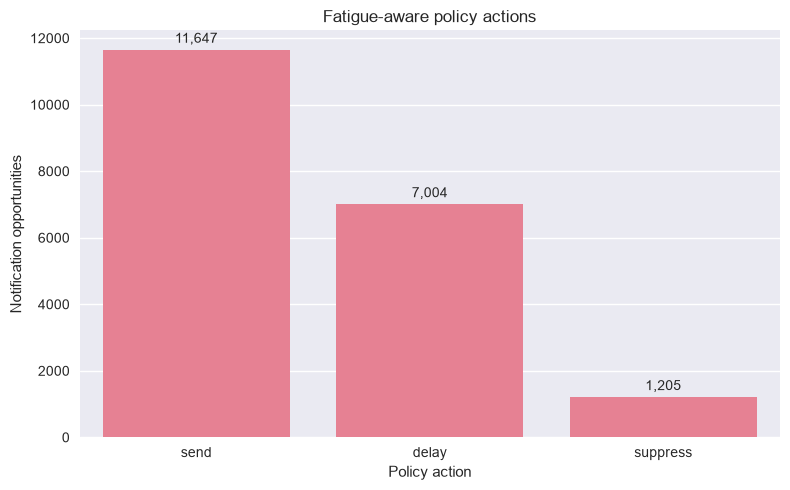

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=action_counts.index, y=action_counts.values, ax=ax)
ax.set(title="Fatigue-aware policy actions", xlabel="Policy action", ylabel="Notification opportunities")
for container in ax.containers:
    ax.bar_label(container, labels=[f"{value:,.0f}" for value in container.datavalues], padding=3)
plt.tight_layout()
plt.show()

The chart describes proposed initial actions only. Rechecking consent, scheduling, exposure and fatigue can change final delivery outcomes.

## Question 2: How do chronological policy scenarios change delivery and engagement?

Run both policies on the same fixed historical March opportunities and keyed random draws. Each simulation maintains independent user state, stops delivery after unsubscribe, and rescores delayed attempts. A delay retries at 09:00 next day and expires after 72 hours or at the exclusive April 1 end. Both scenarios enforce source-compatible spacing and quiet hours. Fatigue transitions are an empirical pre-period approximation, not a recovered generator.

**Common primary KPI:** event-weighted efficiency = total engagements / total delivered notifications. User-weighted efficiency is the mean of individual ratios among recipients and is a selected-population diagnostic. Zero-send ratios remain undefined; assigned users remain in totals and per-user guardrails. Conditional expected metrics sum response probabilities only at actual simulated deliveries, on the realized state path; they do not integrate over alternative fatigue/consent paths. Paired user bootstraps recompute all ratios for each resample.

Expected-on-path fields are probability-sum summaries, not a conditional expectation given the complete future trajectory; later delivery paths depend on earlier draws.

In [10]:
scenario_ledgers = {}
scenario_traces = {}
for policy, arm in [("Baseline", "Control"), ("Fatigue-aware", "Treatment")]:
    mapping = {uid: arm for uid in opportunities["user_id"].unique()}
    ledger, trace, checks = simulate(
        opportunities, history, users, mapping, engagement_response, opt_out_response,
        dynamics, thresholds, simulation_config,
    )
    scenario_ledgers[policy] = ledger
    scenario_traces[policy] = trace
    print(policy, checks)
policy_comparison = pd.DataFrame({
    policy: {
        "eventual_notifications": ledger["sent_notification"].sum(),
        "immediate_notifications": ledger["immediate_notification"].sum(),
        "simulated_engagements": ledger["simulated_engaged"].sum(),
        "simulated_engagement_rate": ledger["simulated_engaged"].sum() / ledger["sent_notification"].sum(),
        "simulated_opt_outs": ledger["simulated_opt_out"].sum(),
    } for policy, ledger in scenario_ledgers.items()
}).T
display(policy_comparison)
policy_comparison.to_csv(project_dir / "data/processed/phase1_policy_scenarios.csv", index_label="policy")
for policy, ledger in scenario_ledgers.items():
    ledger.to_csv(project_dir / f"data/processed/phase1_policy_{policy.lower()}.csv", index=False)

# Common F07 definitions used by both policy and randomized comparisons.
policy_users = {policy: kpi_users(ledger, {uid: ('Control' if policy == 'Baseline' else 'Treatment')
                                        for uid in opportunities.user_id.unique()})
                for policy, ledger in scenario_ledgers.items()}
policy_kpis = pd.concat([kpi_summary(frame).assign(policy=policy) for policy, frame in policy_users.items()])
policy_effects = kpi_contrasts(policy_users['Baseline'], policy_users['Fatigue-aware'], paired=True)
display(policy_kpis)
display(policy_effects)
policy_kpis.to_csv(project_dir / 'data/processed/phase3_policy_kpis.csv', index_label='arm')
policy_effects.to_csv(project_dir / 'data/processed/phase3_policy_contrasts.csv', index_label='metric')
for policy, frame in policy_users.items():
    frame.to_csv(project_dir / f'data/processed/phase3_policy_users_{policy.lower()}.csv', index=False)


Baseline {'candidates': 19856, 'attempts': 19856, 'deliveries_after_unsubscribe': 0, 'engagements_after_unsubscribe': 0, 'chronology_exposure_fatigue_consent_checks': 'passed'}


Fatigue-aware {'candidates': 19856, 'attempts': 32480, 'deliveries_after_unsubscribe': 0, 'engagements_after_unsubscribe': 0, 'chronology_exposure_fatigue_consent_checks': 'passed'}


,eventual_notifications,immediate_notifications,simulated_engagements,simulated_engagement_rate,simulated_opt_outs
Baseline,19774.0,19774.0,7173.0,0.362749,40.0
Fatigue-aware,17856.0,11900.0,6541.0,0.366319,31.0


,assigned_users,recipient_users,zero_send_users,event_weighted_efficiency,user_weighted_efficiency_among_recipients,engagements_per_assigned_user,notifications_per_assigned_user,optouts_per_assigned_user,expected_event_weighted_efficiency_on_path,expected_user_weighted_efficiency_on_path,expected_engagements_per_assigned_user_on_path,policy
arm,,,,,,,,,,,,
Control,4566,4566,0,0.362749,0.361163,1.570959,4.330705,0.008760,0.363976,0.361411,1.576272,Baseline
Treatment,4566,4563,3,0.366319,0.361100,1.432545,3.910644,0.006789,0.367815,0.364296,1.438394,Fatigue-aware


,control,treatment,difference,ci_lower,ci_upper,valid_bootstraps,paired
metric,,,,,,,
event_weighted_efficiency,0.362749,0.366319,0.003570,0.001145,0.005773,2000,True
user_weighted_efficiency_among_recipients,0.361163,0.361100,-0.000063,-0.002146,0.001948,2000,True
engagements_per_assigned_user,1.570959,1.432545,-0.138414,-0.150898,-0.127239,2000,True
notifications_per_assigned_user,4.330705,3.910644,-0.420061,-0.441743,-0.398598,2000,True
optouts_per_assigned_user,0.008760,0.006789,-0.001971,-0.003504,-0.000876,2000,True
expected_event_weighted_efficiency_on_path,0.363976,0.367815,0.003839,0.003405,0.004281,2000,True
expected_user_weighted_efficiency_on_path,0.361411,0.364296,0.002885,0.002655,0.003141,2000,True
expected_engagements_per_assigned_user_on_path,1.576272,1.438394,-0.137878,-0.145608,-0.130493,2000,True


These are paired synthetic scenario realizations with identical candidate traffic and random uniforms. They replace the static volume/expected-engagement comparison. The realized paths depend on the stated fatigue and scheduling assumptions.

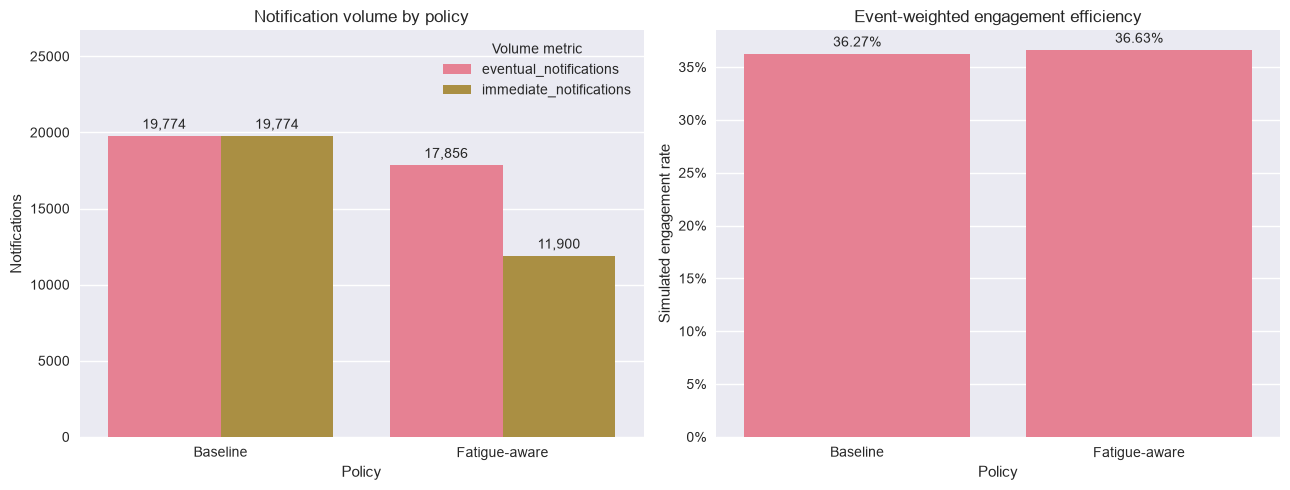

In [11]:
volume_plot = policy_comparison[["eventual_notifications", "immediate_notifications"]].reset_index(
    names="policy"
).melt(id_vars="policy", var_name="metric", value_name="notifications")
rate_plot = policy_comparison["simulated_engagement_rate"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=volume_plot, x="policy", y="notifications", hue="metric", ax=axes[0])
axes[0].set(title="Notification volume by policy", xlabel="Policy", ylabel="Notifications")
for container in axes[0].containers:
    axes[0].bar_label(container, labels=[f"{value:,.0f}" for value in container.datavalues], padding=3)
axes[0].legend(title="Volume metric")
axes[0].set_ylim(0, volume_plot["notifications"].max() * 1.35)  # Reserve space above the annotated bars.

sns.barplot(x=rate_plot.index, y=rate_plot.values, ax=axes[1])
axes[1].set(title="Event-weighted engagement efficiency", xlabel="Policy", ylabel="Simulated engagement rate")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
for container in axes[1].containers:
    axes[1].bar_label(container, labels=[f"{value:.2%}" for value in container.datavalues], padding=3)
plt.tight_layout()
plt.show()

Event-weighted scenario efficiency and realized volume are shown together. Notebook 05 reports the user-randomized comparison separately.

## Question 3: Does the rule protect the high-fatigue immediate-send guardrail?

Compare the share of immediate sends at or above the training-period delay threshold.

In [12]:
guardrail_values = {}
for policy, ledger in scenario_ledgers.items():
    immediate = ledger.loc[ledger["immediate_notification"].eq(1)]
    guardrail_values[policy] = immediate["fatigue_at_terminal"].ge(delay_fatigue).mean()
guardrail = pd.Series(guardrail_values, name="high_fatigue_immediate_share")
display(guardrail.to_frame())

,high_fatigue_immediate_share
Baseline,0.248609
Fatigue-aware,0.000000


This guardrail uses fatigue from the simulated state at delivery. No claim about actual user experience follows from a proxy fatigue rule.

### Terminal outcomes after scheduling

Reconcile every treatment opportunity to a delivered, suppressed, expired or consent-cancelled outcome.

In [13]:
display(scenario_ledgers["Fatigue-aware"].groupby("terminal_status").agg(
    opportunities=("candidate_id", "size"),
    notifications=("sent_notification", "sum"),
    engagements=("simulated_engaged", "sum"),
    opt_outs=("simulated_opt_out", "sum"),
))

,opportunities,notifications,engagements,opt_outs
terminal_status,,,,
cancelled_opt_out,60,0,0,0
delivered,17856,17856,6541,31
expired,1208,0,0,0
suppressed,732,0,0,0


Undelivered opportunities have no simulated notification engagement or opt-out response. Every delayed opportunity resolves or expires inside the declared evaluation horizon.

## Summary

Print the policy tradeoff used by the experiment simulation.

In [14]:
for metric in policy_comparison.columns:
    baseline = policy_comparison.loc["Baseline", metric]
    treatment = policy_comparison.loc["Fatigue-aware", metric]
    print(f"{metric}: baseline={baseline:.6f}, fatigue-aware={treatment:.6f}, difference={treatment-baseline:.6f}")

eventual_notifications: baseline=19774.000000, fatigue-aware=17856.000000, difference=-1918.000000
immediate_notifications: baseline=19774.000000, fatigue-aware=11900.000000, difference=-7874.000000
simulated_engagements: baseline=7173.000000, fatigue-aware=6541.000000, difference=-632.000000
simulated_engagement_rate: baseline=0.362749, fatigue-aware=0.366319, difference=0.003570
simulated_opt_outs: baseline=40.000000, fatigue-aware=31.000000, difference=-9.000000


The printed values are regenerated from the stateful scenarios. The previous static policy percentages are superseded and must not be reused as corrected impact estimates.

## Insights

- Consent is persistent; all future and pending sends are cancelled after simulated unsubscribe.
- Delayed items are rescored with updated fatigue/exposure and may expire.
- Fatigue dynamics and delayed response behavior remain scenario assumptions.
- Fixed historical opportunity traffic does not identify real counterfactual demand or causal policy impact.